# Atividade: Fundamentos de Processamento de Imagens
**Unidade:** 1 | **Capítulo:** 1 | **Atividade:** 1


---

## Objetivo
Construir um mini dataset com 2 classes e 10 imagens no total, aplicando na prática os fundamentos de resolução, espaço de cor, quantização, aquisição e formatos de arquivo, além de analisar o impacto visual e funcional dessas escolhas em tarefas de Visão Computacional.

## Parte 1: Definição das Classes

* **Classe A:** Controle (imagens 001 a 005)
* **Classe B:** Nintendo Switch (imagens 006 a 010)

## Parte 2: Aquisição de Imagens

**Dispositivo utilizado:** Samsung A34 5G (câmera nativa, sem filtros automáticos, embelezamento desativado)

**Cenários de captura (mesmo padrão aplicado às duas classes):**

| Foto | Cenário | Distância/Ângulo |
|---|---|---|
| 1 | Luz natural | Distância curta, foco nos botões analógicos/direcionais |
| 2 | Sombra | Ângulo reto (de cima para baixo) |
| 3 | Luz artificial (noturna) | Distância longa |
| 4 | Luz artificial | Ângulo baixo, de frente (gatilhos superiores) |
| 5 | Luz mista (natural + artificial) | Ângulo inclinado, livre |

**Observações de ruído/desfoque:** leve desfoque perceptível no fundo das imagens (profundidade de campo rasa/bokeh), sem afetar a nitidez do objeto principal.

## Setup Geral (Imports, Drive e Conversão HEIC)

Esta seção realiza a configuração inicial do ambiente de execução. Aqui são feitas as importações das bibliotecas necessárias, a montagem do Google Drive para acessar o dataset e a verificação/conversão de imagens do formato HEIC para formatos compatíveis (como JPG ou PNG) antes do processamento.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from google.colab import drive
drive.mount('/content/drive')

!pip install pillow-heif -q
from pillow_heif import register_heif_opener
from PIL import Image
register_heif_opener()

# Caminho base do dataset
PATH = '/content/drive/MyDrive/dataset'

def converter_pasta(pasta):
    """Converte todos os arquivos .heic de uma pasta para .jpg."""
    for nome_arquivo in os.listdir(pasta):
        nome_sem_ext, ext = os.path.splitext(nome_arquivo)
        if ext.lower() == '.heic':
            caminho = os.path.join(pasta, nome_arquivo)
            img = Image.open(caminho).convert('RGB')
            novo_caminho = os.path.join(pasta, nome_sem_ext + '.jpg')
            img.save(novo_caminho, 'JPEG', quality=95)
            os.remove(caminho)
            print(f'{nome_arquivo} → {nome_sem_ext}.jpg')

converter_pasta(f'{PATH}/classe_A')
converter_pasta(f'{PATH}/classe_B')

print("Classe A:", sorted(os.listdir(f'{PATH}/classe_A')))
print("Classe B:", sorted(os.listdir(f'{PATH}/classe_B')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
img010_original.jpg .heic → img010_original.jpg .jpg
Classe A: ['img001_original.jpg', 'img002_original.jpg', 'img003_original.jpg', 'img004_original.jpg', 'img005_original.jpg']
Classe B: ['img006_original.jpg', 'img007_original.jpg', 'img008_original.jpg', 'img009_original.jpg .jpg', 'img010_original.jpg .jpg']


### Parte A — Análise de Resolução

**Problema:** Avaliar o impacto da redução de resolução (50% e 20%) na percepção visual de detalhes de uma imagem, e discutir possíveis consequências para tarefas de Visão Computacional.

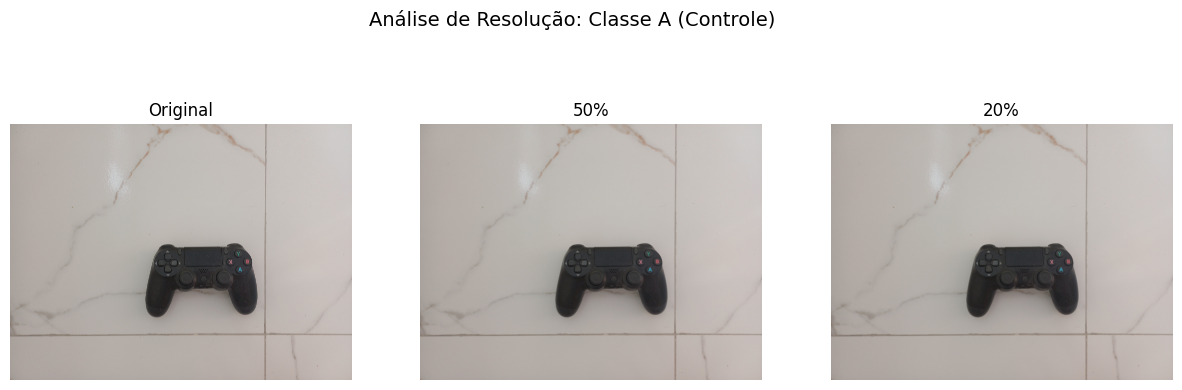

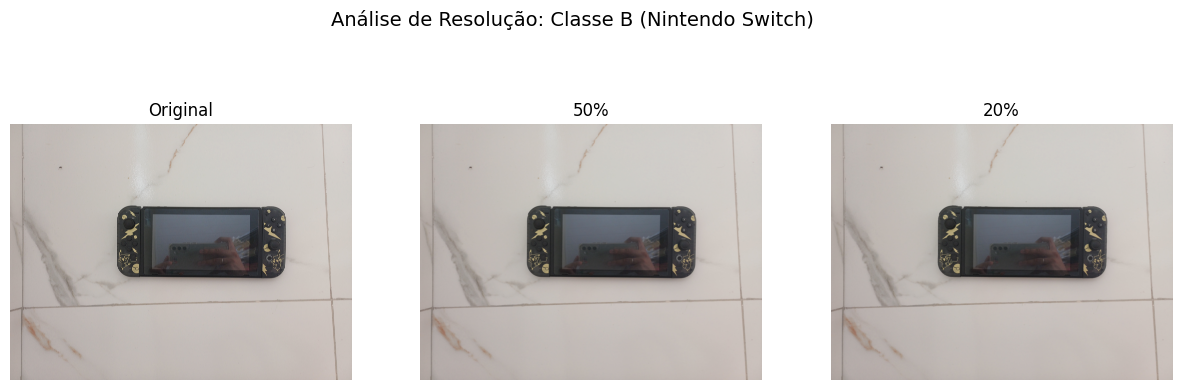

In [ ]:
def analisar_resolucao(caminho_img, titulo_classe):
    img = cv2.imread(caminho_img)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    altura, largura = img.shape[:2]

    img_50 = cv2.resize(img, (largura//2, altura//2))
    img_20 = cv2.resize(img, (largura//5, altura//5))

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"Análise de Resolução: {titulo_classe}", fontsize=14)

    ax[0].imshow(img)
    ax[0].set_title("Original")

    ax[1].imshow(img_50)
    ax[1].set_title("50%")

    ax[2].imshow(img_20)
    ax[2].set_title("20%")

    for a in ax:
        a.axis('off')

    plt.show()

caminho_A = os.path.join(PATH, 'classe_A/img001_original.jpg')
caminho_B = os.path.join(PATH, 'classe_B/img006_original.jpg')

analisar_resolucao(caminho_A, "Classe A (Controle)")
analisar_resolucao(caminho_B, "Classe B (Nintendo Switch)")

## Interpretação — Análise de Resolução

Ao reduzir a resolução das imagens, observa-se uma perda progressiva de detalhes finos.

Na versão com 50% de resolução, houve uma drástica redução na qualidade, ficando difícil visualizar a borracha na parte inferior do controle, além de detalhes como os furos e o botão *Home*. Já no Nintendo Switch, os botões tanto do lado esquerdo quanto do direito ficaram mais difíceis de enxergar, além da dificuldade em distinguir as letras dos botões Y, X, B e A.

Na versão com 20%, ficou ainda mais difícil enxergar os detalhes gerais. Os botões tornaram-se difíceis de perceber e os detalhes da textura da borracha dos analógicos — tanto do Switch quanto do controle — ficaram praticamente imperceptíveis. No Switch, a visualização dos botões esquerdos e a leitura das letras em ambos os dispositivos foi severamente comprometida.

Esse tipo de degradação da imagem pode prejudicar tarefas de visão computacional, tais como:
* Reconhecimento de objetos;
* Segmentação de instâncias;
* Extração de características e bordas;
* Classificação automática.

Em uma tarefa real de classificação Controle vs. Switch, a versão com **50% de resolução** provavelmente ainda manteria uma boa acurácia, pois a forma global geométrica, a silhueta dos dois objetos e a presença da tela central no Switch são características macroscópicas muito diferentes. Portanto, mesmo com a perda de detalhes finos (como as letras dos botões), o formato principal continua perfeitamente distinguível para o modelo.

Já a versão com **20% de resolução** começaria a comprometer o desempenho do algoritmo, pois o nível de pixelização destrói as bordas dos objetos e mistura o contorno dos aparelhos com o fundo. A perda drástica de informações de alta frequência (contornos nítidos e cantos) faria com que os extratores de características falhassem, podendo fazer o modelo confundir os dois objetos dependendo do ângulo da foto e das condições de iluminação.

### B. Espaço de Cor

**Problema:** converter uma imagem de cada classe para RGB, HSV e Escala de Cinza, e analisar as diferenças visuais e as aplicações de cada espaço de cor.

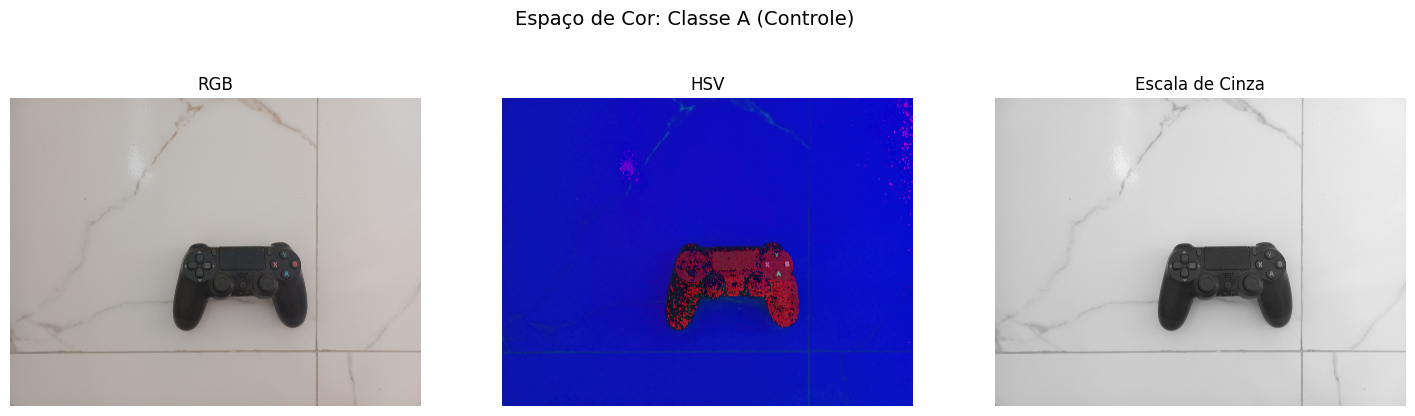

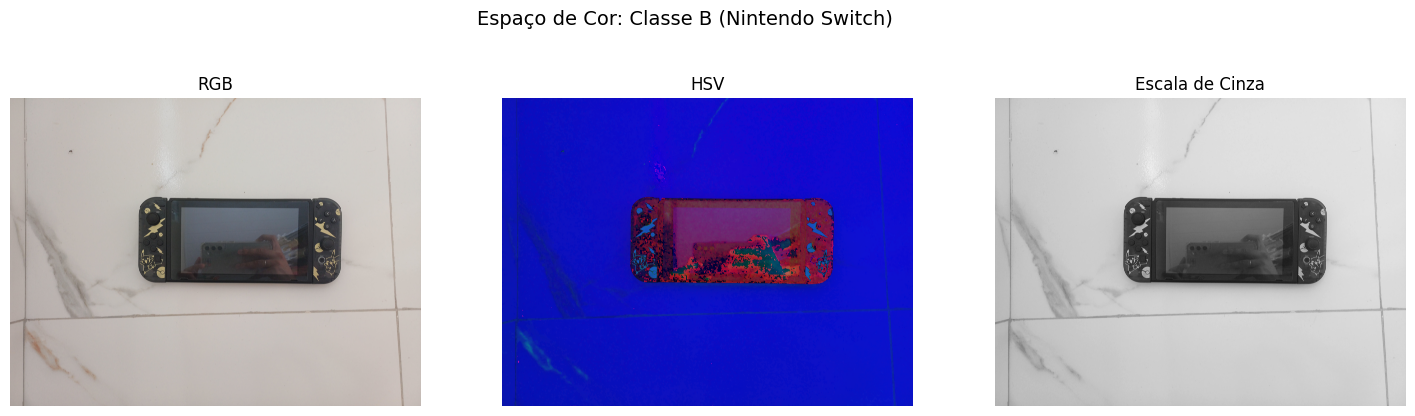

In [ ]:
def analisar_espaco_cor(caminho_img, titulo_classe):
    img_bgr = cv2.imread(caminho_img)

    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Espaço de Cor: {titulo_classe}", fontsize=14)

    ax[0].imshow(rgb)
    ax[0].set_title("RGB")

    ax[1].imshow(hsv)
    ax[1].set_title("HSV")

    ax[2].imshow(gray, cmap='gray')
    ax[2].set_title("Escala de Cinza")

    for a in ax:
        a.axis('off')

    plt.show()

analisar_espaco_cor(caminho_A, "Classe A (Controle)")
analisar_espaco_cor(caminho_B, "Classe B (Nintendo Switch)")

## Diferenças visuais observadas

**RGB:** mantém as cores naturais da imagem, como capturadas pela câmera.

HSV: Separa a cor da intensidade da luz, o que gera um aspecto visualmente "esquisito" quando a imagem é renderizada na tela. É possível notar que a ceramica do fundo (originalmente branco) ficou azul intenso, enquanto os plásticos escuros e grafites (tanto no controle quanto no Nintendo Switch) ganharam tons avermelhados. Isso ocorre porque o software de visualização está interpretando os canais de Matiz (Hue), Saturação (Saturation) e Valor/Brilho (Value) como se fossem cores diretas.

**Escala de cinza:** remove toda informação de cor, mantendo apenas intensidade luminosa.

## Aplicações de cada espaço de cor

- **RGB:** classificação de objetos, visualização convencional
- **HSV:** detecção de cores, segmentação e rastreamento de objetos
- **Escala de cinza:** detecção de bordas, redução de custo computacional

### C. Quantização

**Problema:** gerar versões de uma imagem de cada classe com 256, 64, 32 e 2 níveis de cinza, e analisar o impacto visual e funcional dessa redução.

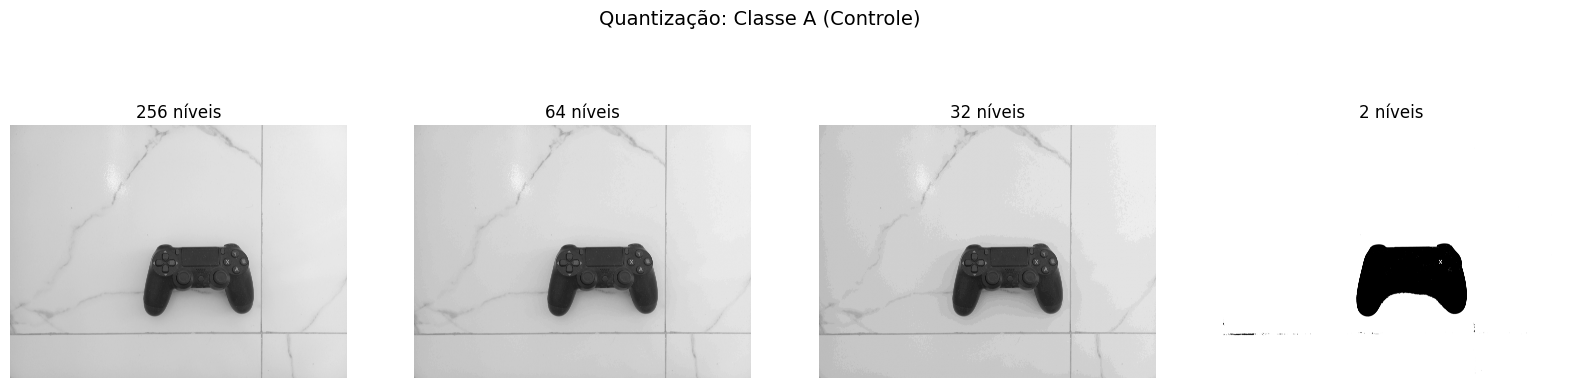

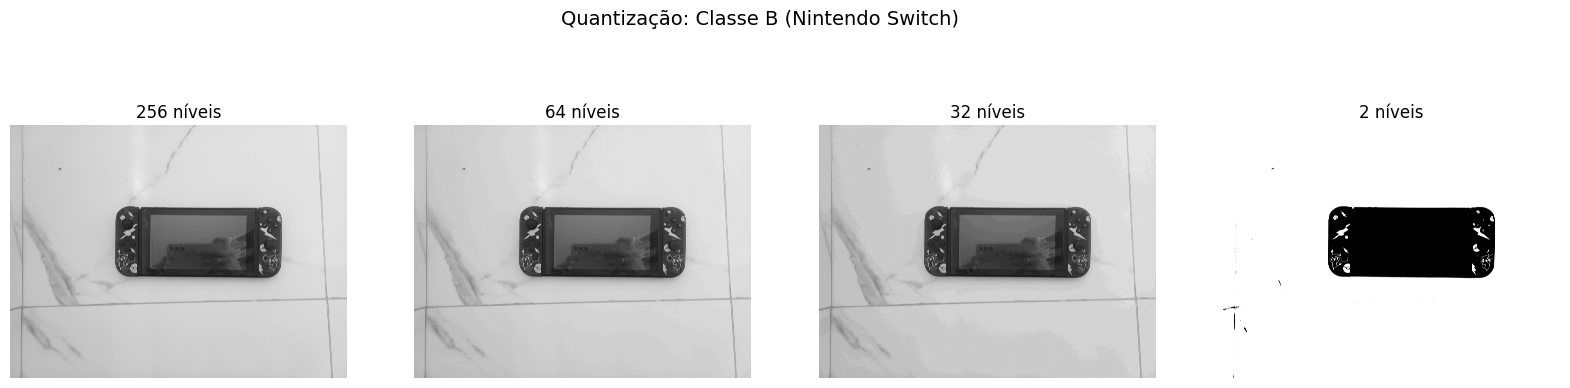

In [ ]:
def analisar_quantizacao(caminho_img, titulo_classe):
    img = cv2.imread(caminho_img, 0)  # já carrega em escala de cinza

    q64 = (img // 4) * 4
    q32 = (img // 8) * 8
    q2 = ((img > 127) * 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(f"Quantização: {titulo_classe}", fontsize=14)

    ax[0].imshow(img, cmap='gray')
    ax[0].set_title("256 níveis")

    ax[1].imshow(q64, cmap='gray')
    ax[1].set_title("64 níveis")

    ax[2].imshow(q32, cmap='gray')
    ax[2].set_title("32 níveis")

    ax[3].imshow(q2, cmap='gray')
    ax[3].set_title("2 níveis")

    for a in ax:
        a.axis('off')

    plt.show()

analisar_quantizacao(caminho_A, "Classe A (Controle)")
analisar_quantizacao(caminho_B, "Classe B (Nintendo Switch)")

## Observações sobre a Quantização

Com a redução dos níveis de cinza, observa-se uma perda gradual de detalhes, como nas texturas das borrachas e nos botões de ambos os aparelhos. As regiões tornam-se mais "chapadas" (efeito conhecido como posterização), ocorre um aumento de contraste na área do fundo, e os gradientes que antes variavam entre preto e cinza escuro fundiram-se em tons de preto sólido.

* **A versão com 64 níveis:** Mesmo reduzindo a quantidade de tons para 1/4 (em relação aos 256 originais), a imagem ainda se mantém bem semelhante à original. É possível visualizar os detalhes dos botões e analógicos tanto do Switch quanto do controle. Nota-se uma leve "fusão" em detalhes que possuíam tons muito próximos, mas a preservação visual e estrutural do objeto continua excelente.

* **A versão com 2 níveis (Binarização):** A imagem é reduzida estritamente a preto e branco absoluto. No controle, o algoritmo associou a refletividade de dois botões ao branco, deixando apenas essas pequenas marcações visíveis contra o corpo totalmente preto do aparelho. A cerâmica do fundo ficou completamente branca, perdendo os detalhes e veios do mármore. Já no Switch, a tela e o corpo tornaram-se um bloco preto maciço, enquanto os detalhes mais claros da arte de Pokémon nos Joy-Cons foram convertidos para branco, destacando-se contra o fundo liso.

### Qual versão seria mais útil para o dataset e para qual aplicação?

* **As versões de 256 ou 64 níveis** seriam as mais úteis para **classificação de objetos e extração de características complexas**. A versão de 64 níveis, em especial, oferece um excelente custo-benefício: ela reduz o espaço de armazenamento e a complexidade dos dados (ideal para otimizar o processamento) sem perder características cruciais como a textura dos analógicos e a disposição dos botões.
* **A versão de 2 níveis** seria extremamente útil para **segmentação de imagem, extração de contornos e detecção de silhueta (Bounding Box)**. Ao transformar a imagem em preto e branco, torna-se muito mais simples e rápido para o computador separar o que é "fundo" (branco) do que é o "objeto de interesse" (preto). No entanto, ela seria péssima para classificação fina, pois destrói quase todas as informações internas de textura e design que diferenciam os dois aparelhos.

### D. Formato de Arquivo

**Problema:** salvar uma imagem de cada classe em JPEG (com compressão) e PNG (sem perdas), comparando o tamanho final dos arquivos e levantando hipóteses sobre o impacto em tarefas de Processamento Digital de Imagens.

In [ ]:
def analisar_formatos(caminho_img, titulo_classe):
    img = cv2.imread(caminho_img)

    nome_jpg = f"{titulo_classe.replace(' ', '_')}_compressao.jpg"
    nome_png = f"{titulo_classe.replace(' ', '_')}_sem_perda.png"

    cv2.imwrite(nome_jpg, img, [cv2.IMWRITE_JPEG_QUALITY, 30])
    cv2.imwrite(nome_png, img)

    tamanho_jpg = os.path.getsize(nome_jpg) / 1024
    tamanho_png = os.path.getsize(nome_png) / 1024

    print(f"--- {titulo_classe} ---")
    print(f"Tamanho JPEG (compressão): {tamanho_jpg:.2f} KB")
    print(f"Tamanho PNG (sem perdas): {tamanho_png:.2f} KB")
    print("-" * 30)

analisar_formatos(caminho_A, "Classe A - Controle")
analisar_formatos(caminho_B, "Classe B - Switch")

--- Classe A - Controle ---
Tamanho JPEG (compressão): 817.53 KB
Tamanho PNG (sem perdas): 12811.59 KB
------------------------------
--- Classe B - Switch ---
Tamanho JPEG (compressão): 846.23 KB
Tamanho PNG (sem perdas): 12632.37 KB
------------------------------


## Comparação de Formatos de Arquivo

* **Tamanho do arquivo:** Houve uma redução drástica de armazenamento ao utilizar a compressão. Na Classe A (Controle), o JPEG ocupou apenas **817.53 KB**, enquanto o PNG exigiu **12811.59 KB** (aprox. 12.8 MB). Na Classe B (Switch), o JPEG ficou com **846.23 KB**, contra **12632.37 KB** (aprox. 12.6 MB) do PNG. Em média, o arquivo PNG consumiu cerca de 15 vezes mais espaço que o JPEG.

* **Diferença visual percebida:** O formato PNG (compressão sem perdas / *lossless*) manteve a nitidez absoluta dos pixels, das texturas e a suavidade do fundo. Já no formato JPEG (compressão com perdas / *lossy*), dependendo do nível de qualidade aplicado, é possível notar o surgimento de leves artefatos de compressão (pequenos blocos ou "sujeiras" nos pixels), especialmente nas bordas dos aparelhos e nos contrastes fortes entre o plástico escuro e a cerâmica clara do fundo.

* **Hipótese sobre o impacto em tarefas de PDI (Visão Computacional):**
  * O formato **JPEG** é excelente para economia de espaço em disco e velocidade de leitura (I/O) dos dados, o que acelera significativamente o carregamento de *batches* durante o treinamento de redes neurais em datasets gigantes. Contudo, os artefatos de compressão introduzem "ruídos" artificiais que podem prejudicar algoritmos tradicionais baseados em gradientes, extração de bordas (como filtros de Canny/Sobel) e tarefas que exigem alta precisão microscópica.
  * O formato **PNG** preserva a fidelidade estrutural máxima, sendo a escolha ideal para tarefas onde cada pixel importa, como segmentação semântica precisa, análise médica ou inspeção industrial de defeitos. A desvantagem é o alto custo computacional: consome muita memória RAM e pode se tornar um gargalo de velocidade na leitura dos dados do disco para a GPU em datasets muito grandes.

## Parte 4: Estrutura do Mini Dataset

**Problema:** organizar as 10 imagens capturadas em uma estrutura de pastas padrão para projetos de Machine Learning (`dataset/classe_A/` e `dataset/classe_B/`), com nomes de arquivo padronizados.

In [ ]:
def padronizar_nomes(pasta, prefixo_inicio):
    """Renomeia os arquivos da pasta para o padrão imgXXX_original.jpg"""
    arquivos = sorted([f for f in os.listdir(pasta) if f.lower().endswith('.jpg')])
    for i, nome_antigo in enumerate(arquivos, start=prefixo_inicio):
        novo_nome = f"img{i:03d}_original.jpg"
        caminho_antigo = os.path.join(pasta, nome_antigo)
        caminho_novo = os.path.join(pasta, novo_nome)
        if nome_antigo != novo_nome:
            os.rename(caminho_antigo, caminho_novo)
            print(f"{nome_antigo} → {novo_nome}")

padronizar_nomes(f'{PATH}/classe_A', 1)   # gera img001 a img005
padronizar_nomes(f'{PATH}/classe_B', 6)   # gera img006 a img010

print("Classe A:", sorted(os.listdir(f'{PATH}/classe_A')))
print("Classe B:", sorted(os.listdir(f'{PATH}/classe_B')))

img009_original.jpg .jpg → img009_original.jpg
img010_original.jpg .jpg → img010_original.jpg
Classe A: ['img001_original.jpg', 'img002_original.jpg', 'img003_original.jpg', 'img004_original.jpg', 'img005_original.jpg']
Classe B: ['img006_original.jpg', 'img007_original.jpg', 'img008_original.jpg', 'img009_original.jpg', 'img010_original.jpg']


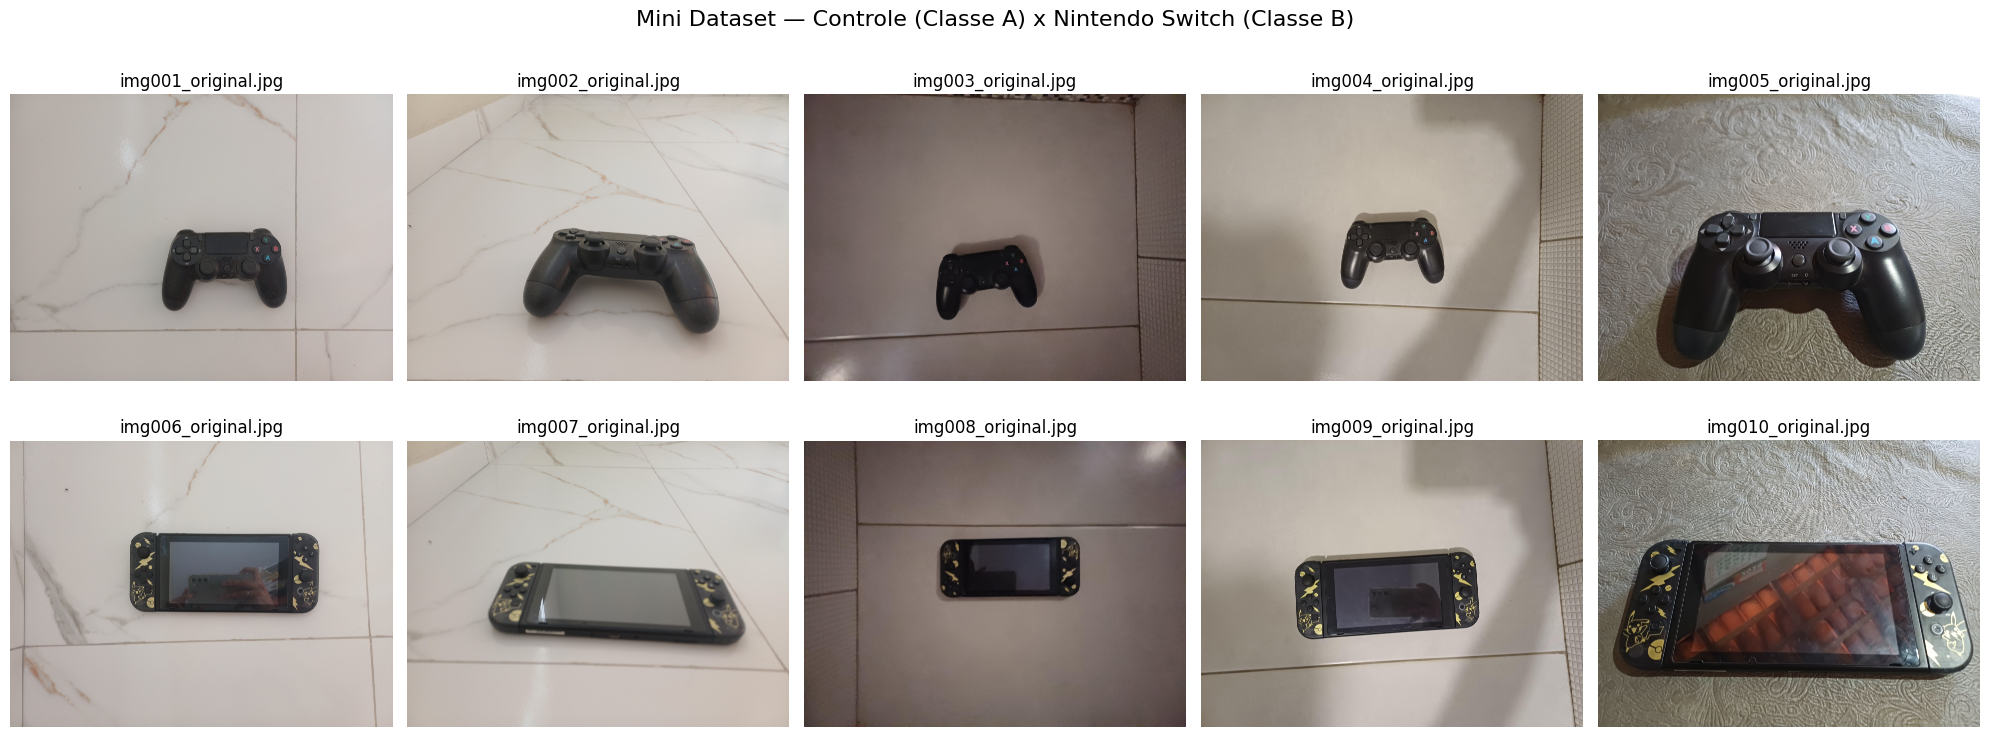

In [ ]:
def exibir_dataset(pasta_A, pasta_B):
    # Filtra apenas imagens válidas e pega as 5 primeiras para não dar erro no plot
    imagens_A = sorted([f for f in os.listdir(pasta_A) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])[:5]
    imagens_B = sorted([f for f in os.listdir(pasta_B) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])[:5]

    fig, ax = plt.subplots(2, 5, figsize=(20, 8))
    fig.suptitle("Mini Dataset — Controle (Classe A) x Nintendo Switch (Classe B)", fontsize=16)

    for i, nome in enumerate(imagens_A):
        img = cv2.imread(os.path.join(pasta_A, nome))
        if img is not None: # Trava de segurança
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax[0, i].imshow(img)
        ax[0, i].set_title(nome)
        ax[0, i].axis('off')

    for i, nome in enumerate(imagens_B):
        img = cv2.imread(os.path.join(pasta_B, nome))
        if img is not None: # Trava de segurança
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax[1, i].imshow(img)
        ax[1, i].set_title(nome)
        ax[1, i].axis('off')

    plt.tight_layout()
    plt.show()

exibir_dataset(f'{PATH}/classe_A', f'{PATH}/classe_B')